In [ ]:
import pandas as pd

df = pd.read_csv('https://raw.githubusercontent.com/ganjar87/data_science_practice/main/Tweets.csv', delimiter=',')
df.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [ ]:
df.shape

(14640, 15)

In [ ]:
df_resize = df.iloc[:1000]
df_resize.shape

(1000, 15)

In [ ]:
df_resize = df_resize[df_resize.airline_sentiment    != 'neutral']

In [ ]:
df_resize.shape

(728, 15)

In [ ]:
df_resize.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)
5,570300767074181121,negative,1.0000,Can't Tell,0.6842,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica seriously would pay $30 a fligh...,NaN,2015-02-24 11:14:33 -0800,NaN,Pacific Time (US & Canada)
6,570300616901320704,positive,0.6745,NaN,0.0000,Virgin America,NaN,cjmcginnis,NaN,0,"@VirginAmerica yes, nearly every time I fly VX...",NaN,2015-02-24 11:13:57 -0800,San Francisco CA,Pacific Time (US & Canada)


In [ ]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab') # Added to download the missing resource
from nltk.tokenize import word_tokenize

df_text = df_resize['text'].astype(str)
df_class = df_resize['airline_sentiment']
lines = df_text.values.tolist()

list_tokens = list()
for line in lines:
 line = line.replace("@VirginAmerica","")
 line = line.replace("@united","")
 tokens = word_tokenize(line)
 list_tokens.append(tokens)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [ ]:
list_tokens[103]

['having',
 'problems',
 'Flight',
 'Booking',
 'Problems',
 'on',
 'the',
 'web',
 'site',
 '.',
 'keeps',
 'giving',
 'me',
 'an',
 'error',
 'and',
 'to',
 'contact',
 'by',
 'phone',
 '.',
 'phone',
 'is',
 '30',
 'minute',
 'wait',
 '.']

In [ ]:
import nltk
nltk.download('punkt')
from nltk.tokenize import word_tokenize
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

df_text = df_resize['text'].astype(str)
df_class = df_resize['airline_sentiment']
lines = df_text.values.tolist()
list_tokens_stem = list()
porter = PorterStemmer()

for line in lines:
 line = line.replace("@VirginAmerica","")
 line = line.replace("@united","")
 tokens = word_tokenize(line)
 # merubah tokens menjadi huruf kecil semua
 tokens = [w.lower() for w in tokens]
 tokens = [word for word in tokens if word.isalpha()]
 # menghapus stop words
 tokens = [word for word in tokens if not word in stopwords.words()]
 # melakukan stemming
 tokens = [porter.stem(word) for word in tokens]
 list_tokens_stem.append(tokens)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
print(lines[103])
print(list_tokens_stem[103])

@VirginAmerica having problems Flight Booking Problems on the web site. keeps giving me an error and to contact by phone.  phone is 30 minute wait.
['problem', 'flight', 'book', 'problem', 'web', 'site', 'give', 'error', 'contact', 'phone', 'phone', 'minut', 'wait']


In [ ]:
import nltk
nltk.download('punkt')
from nltk.tokenize import word_tokenize
nltk.download('stopwords')
from nltk.corpus import stopwords
#from nltk.stem import PorterStemmer

nltk.download('wordnet')
from nltk.stem import WordNetLemmatizer

df_text = df_resize['text'].astype(str)
df_class = df_resize['airline_sentiment']
lines = df_text.values.tolist()
list_tokens_lemma = list()
#porter = PorterStemmer()
lemmatizer = WordNetLemmatizer()

for line in lines:
 line = line.replace("@VirginAmerica","")
 line = line.replace("@united","")
 tokens = word_tokenize(line)
 # merubah tokens menjadi huruf kecil semua
 tokens = [w.lower() for w in tokens]
 tokens = [word for word in tokens if word.isalpha()]
 # menghapus stop words
 tokens = [word for word in tokens if not word in stopwords.words()]
 # melakukan stemming
 #tokens = [porter.stem(word) for word in tokens]
 # melakukan lemmatization
 tokens = [lemmatizer.lemmatize(word) for word in tokens]

 list_tokens_lemma.append(tokens)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...


In [ ]:
list_tokens_lemma[103]

['problem',
 'flight',
 'booking',
 'problem',
 'web',
 'site',
 'giving',
 'error',
 'contact',
 'phone',
 'phone',
 'minute',
 'wait']

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

new_doc = list()
#ambil dari hasil lemmatization misalnya
for doc in list_tokens_lemma:
 row = ' '.join(doc)
 new_doc.append(row)

vectorizer = CountVectorizer(max_features=1000)
X_input_bow = vectorizer.fit_transform(new_doc)

In [ ]:
list_tokens_lemma[:10]

[['added', 'commercial', 'experience', 'tacky'],
 ['aggressive',
  'blast',
  'obnoxious',
  'entertainment',
  'guest',
  'face',
  'amp',
  'recourse'],
 ['big'],
 ['pay', 'flight', 'seat', 'playing', 'flying'],
 ['time', 'fly', 'vx', 'ear', 'worm', 'away'],
 ['virginamerica'],
 ['amazing', 'arrived', 'hour', 'early'],
 ['lt', 'pretty', 'graphic', 'minimal', 'iconography'],
 ['great', 'deal', 'trip', 'australia', 'amp', 'trip', 'p'],
 ['virginmedia',
  'flying',
  'fabulous',
  'seductive',
  'sky',
  'stress',
  'away',
  'travel',
  'http']]

In [ ]:
new_doc[:10]

['added commercial experience tacky',
 'aggressive blast obnoxious entertainment guest face amp recourse',
 'big',
 'pay flight seat playing flying',
 'time fly vx ear worm away',
 'virginamerica',
 'amazing arrived hour early',
 'lt pretty graphic minimal iconography',
 'great deal trip australia amp trip p',
 'virginmedia flying fabulous seductive sky stress away travel http']

In [ ]:
print(vectorizer.get_feature_names_out())
print(X_input_bow.toarray())
print(vectorizer.vocabulary_)
print(X_input_bow.shape)

['ability' 'absolute' 'absolutely' 'absurd' 'abt' 'abundance' 'accelerate'
 'accept' 'access' 'accident' 'accompany' 'account' 'accountable' 'acosta'
 'action' 'active' 'add' 'added' 'adding' 'additional' 'address' 'advance'
 'afford' 'agent' 'ago' 'ahead' 'air' 'aircraft' 'airline' 'airport'
 'amazing' 'america' 'americanair' 'amp' 'angry' 'answer' 'answering'
 'anxiety' 'apology' 'app' 'apparently' 'applied' 'appreciate'
 'appropriate' 'arrived' 'arrives' 'arriving' 'asap' 'ase' 'asked'
 'assist' 'assistance' 'atrocious' 'attendant' 'austin' 'avail'
 'available' 'aviv' 'award' 'away' 'awesome' 'back' 'bag' 'baggage' 'bank'
 'bday' 'big' 'bin' 'birthday' 'bit' 'board' 'boarded' 'boarding' 'book'
 'booked' 'booking' 'bos' 'boston' 'bought' 'brand' 'break' 'broken'
 'browser' 'bug' 'business' 'button' 'buy' 'cabin' 'cake' 'call' 'called'
 'calling' 'cancelled' 'captain' 'car' 'card' 'carrier' 'carrieunderwood'
 'carry' 'carseat' 'case' 'caused' 'center' 'central' 'challenge' 'chance'
 '

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

new_doc = list()
# ambil dari hasil lemmatization misalnya
for doc in list_tokens_lemma:
 row = ' '.join(doc)
 new_doc.append(row)

tfidf_vectorizer = TfidfVectorizer(max_features=1000)
X_input_tfidf = tfidf_vectorizer.fit_transform(new_doc)

In [ ]:
print(tfidf_vectorizer.get_feature_names_out())
print(X_input_tfidf.toarray())
print(tfidf_vectorizer.vocabulary_)
print(X_input_tfidf.shape)

['ability' 'absolute' 'absolutely' 'absurd' 'abt' 'abundance' 'accelerate'
 'accept' 'access' 'accident' 'accompany' 'account' 'accountable' 'acosta'
 'action' 'active' 'add' 'added' 'adding' 'additional' 'address' 'advance'
 'afford' 'agent' 'ago' 'ahead' 'air' 'aircraft' 'airline' 'airport'
 'amazing' 'america' 'americanair' 'amp' 'angry' 'answer' 'answering'
 'anxiety' 'apology' 'app' 'apparently' 'applied' 'appreciate'
 'appropriate' 'arrived' 'arrives' 'arriving' 'asap' 'ase' 'asked'
 'assist' 'assistance' 'atrocious' 'attendant' 'austin' 'avail'
 'available' 'aviv' 'award' 'away' 'awesome' 'back' 'bag' 'baggage' 'bank'
 'bday' 'big' 'bin' 'birthday' 'bit' 'board' 'boarded' 'boarding' 'book'
 'booked' 'booking' 'bos' 'boston' 'bought' 'brand' 'break' 'broken'
 'browser' 'bug' 'business' 'button' 'buy' 'cabin' 'cake' 'call' 'called'
 'calling' 'cancelled' 'captain' 'car' 'card' 'carrier' 'carrieunderwood'
 'carry' 'carseat' 'case' 'caused' 'center' 'central' 'challenge' 'chance'
 '

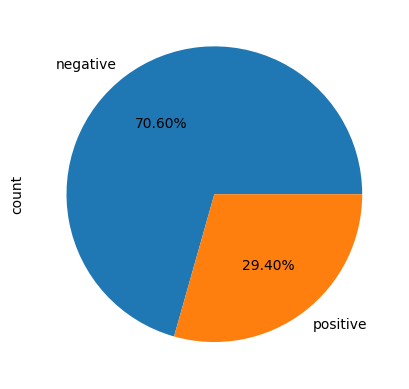

In [ ]:
import matplotlib.pyplot as plt

data = df_resize['airline_sentiment'].value_counts()
data.plot(kind='pie',autopct='%.2f%%')
plt.show()

Accuracy  0.8401826484018264
Precision  0.8121184371184371
Recall  0.8037730243612597
Confusion matrix  [[137  16]
 [ 19  47]]
F1  0.807706781064198


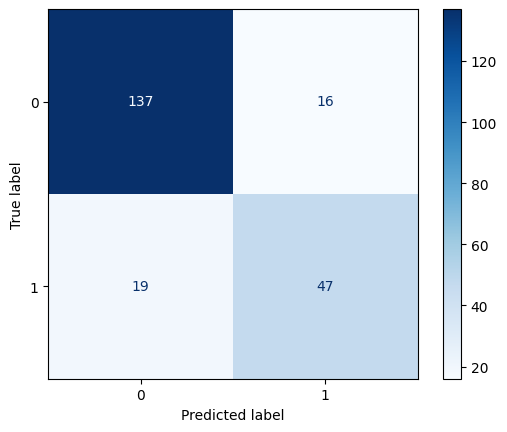

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from imblearn.metrics import sensitivity_specificity_support
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPClassifier
import numpy as np


# get X and y
df_X = X_input_bow
df_y = df_resize['airline_sentiment']

#hold out, dibagi menjadi training dan testing set
X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.3, random_state=42)

#label encoding for y
le = LabelEncoder()
le.fit(y_train)
y_train=le.transform(y_train)
y_test=le.fit_transform(y_test)

#mulai learning
model=MLPClassifier(max_iter=1000)
#model=MLPClassifier(max_iter=1000, random_state=42, activation='logistic')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print('Accuracy ',accuracy_score(y_test, y_pred))
print('Precision ',precision_score(y_test, y_pred, average='macro'))
print('Recall ',recall_score(y_test, y_pred, average='macro'))
print('Confusion matrix ', confusion_matrix(y_test, y_pred))
# plot_confusion_matrix(model, X_test, y_test, cmap=plt.cm.Blues)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))
# plt.show()
disp.plot(cmap=plt.cm.Blues)

from sklearn.metrics import f1_score
print('F1 ',f1_score(y_test, y_pred, average='macro'))

In [ ]:
df_X.shape

(728, 1000)

Accuracy  0.8401826484018264
Precision  0.7627118644067796
Recall  0.6818181818181818
Confusion matrix  [[139  14]
 [ 21  45]]
F1  0.8040894568690096


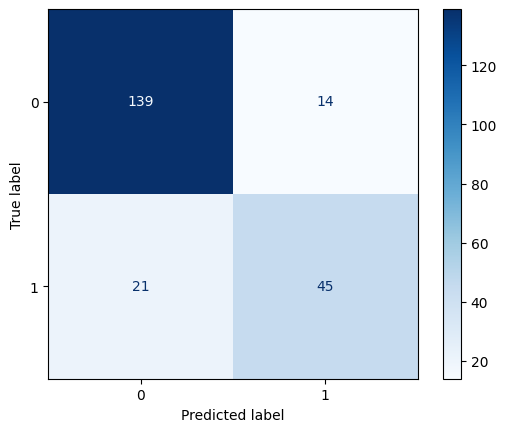

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix

from imblearn.metrics import sensitivity_specificity_support
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPClassifier


# get X and y
df_X = X_input_tfidf
df_y = df_resize['airline_sentiment']

#hold out, dibagi menjadi training dan testing set
X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.3, random_state=42)

#label encoding for y
le = LabelEncoder()
le.fit(y_train)
y_train=le.transform(y_train)
y_test=le.fit_transform(y_test)

#mulai learning
model=MLPClassifier(max_iter=1000)
#model=MLPClassifier(max_iter=1000, random_state=42, activation='logistic')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print('Accuracy ',accuracy_score(y_test, y_pred))
print('Precision ',precision_score(y_test, y_pred))
print('Recall ',recall_score(y_test, y_pred))
print('Confusion matrix ', confusion_matrix(y_test, y_pred))
# plot_confusion_matrix(model, X_test, y_test, cmap=plt.cm.Blues)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))
# plt.show()
disp.plot(cmap=plt.cm.Blues)

from sklearn.metrics import f1_score
print('F1 ',f1_score(y_test, y_pred, average='macro'))


Accuracy  0.7351598173515982
Precision  0.5465116279069767
Recall  0.7121212121212122
Confusion matrix  [[114  39]
 [ 19  47]]
F1  0.7078119249171881


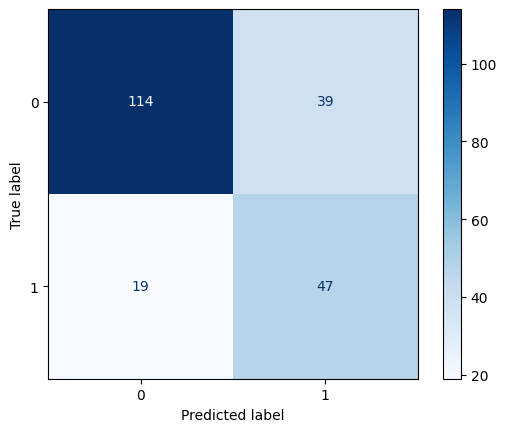

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix

from imblearn.metrics import sensitivity_specificity_support
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier


# get X and y
df_X = X_input_bow
df_y = df_resize['airline_sentiment']

#hold out, dibagi menjadi training dan testing set
X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.3, random_state=42)

#label encoding for y
le = LabelEncoder()
le.fit(y_train)
y_train=le.transform(y_train)
y_test=le.fit_transform(y_test)


#mulai learning
model=DecisionTreeClassifier()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print('Accuracy ',accuracy_score(y_test, y_pred))
print('Precision ',precision_score(y_test, y_pred))
print('Recall ',recall_score(y_test, y_pred))
print('Confusion matrix ', confusion_matrix(y_test, y_pred))
# plot_confusion_matrix(model, X_test, y_test, cmap=plt.cm.Blues)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))
# plt.show()
disp.plot(cmap=plt.cm.Blues)

from sklearn.metrics import f1_score
print('F1 ',f1_score(y_test, y_pred, average='macro'))

Accuracy  0.726027397260274
Precision  0.5340909090909091
Recall  0.7121212121212122
Confusion matrix  [[112  41]
 [ 19  47]]
F1  0.6995610023779038


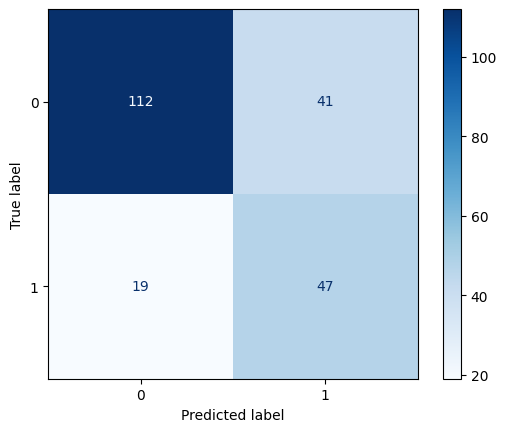

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix

from imblearn.metrics import sensitivity_specificity_support
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier


# get X and y
df_X = X_input_tfidf
df_y = df_resize['airline_sentiment']

#hold out, dibagi menjadi training dan testing set
X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.3, random_state=42)

#label encoding for y
le = LabelEncoder()
le.fit(y_train)
y_train=le.transform(y_train)
y_test=le.fit_transform(y_test)


#mulai learning
model=DecisionTreeClassifier()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print('Accuracy ',accuracy_score(y_test, y_pred))
print('Precision ',precision_score(y_test, y_pred))
print('Recall ',recall_score(y_test, y_pred))
print('Confusion matrix ', confusion_matrix(y_test, y_pred))
# plot_confusion_matrix(model, X_test, y_test, cmap=plt.cm.Blues)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))
# plt.show()
disp.plot(cmap=plt.cm.Blues)

from sklearn.metrics import f1_score
print('F1 ',f1_score(y_test, y_pred, average='macro'))


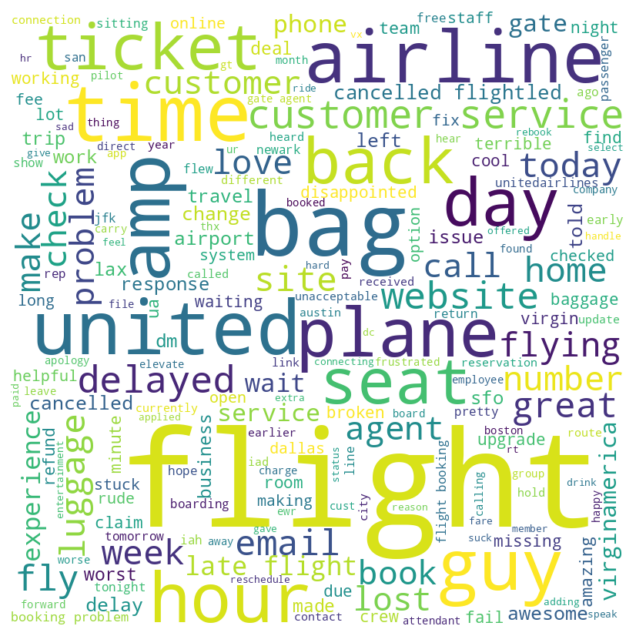

In [ ]:
from wordcloud import WordCloud

text = ' '.join(new_doc)
wordcloud = WordCloud(width = 800, height = 800, background_color="white")
wordcloud = wordcloud.generate_from_text(text)
# Display the generated image:
plt.figure(figsize=(8, 8), dpi=100)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()

In [ ]:
text

'added commercial experience tacky aggressive blast obnoxious entertainment guest face amp recourse big pay flight seat playing flying time fly vx ear worm away virginamerica amazing arrived hour early lt pretty graphic minimal iconography great deal trip australia amp trip p virginmedia flying fabulous seductive sky stress away travel http  schedule excited cross country flight lax mco heard great thing virgin america flew nyc sfo week fully seat due large gentleman side flying amazingly awesome fly fare time carrier seat available select love graphic http love hipster innovation feel brand guy messed seating reserved seating friend guy gave seat away free internet status match program applied week called emailed response happened ur vegan food option ur site eat hr fail amazing cold air vent noair worstflightever roasted sfotobos bked cool birthday trip add elevate entered middle flight booking problem left expensive headphone flight iad lax today seat answering amp f number lax awai

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Load Dataset langsung dari URL
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_csv(url, sep='\t', header=None, names=['label', 'message'])

print("Dimensi Awal:", df.shape)
display(df.head())

Dimensi Awal: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
# Ambil 1000 baris saja
df_small = df.iloc[:1000]
print("Dimensi Setelah Resize:", df_small.shape)

# Feature Extraction menggunakan TF-IDF
# Stopwords bahasa inggris dihapus, maksimal fitur dibatasi 1000 kata terpopuler
tfidf = TfidfVectorizer(stop_words='english', max_features=1000)
X = tfidf.fit_transform(df_small['message']).toarray()
y = df_small['label']

# Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Preprocessing selesai. Siap training.")

Dimensi Setelah Resize: (1000, 2)
Preprocessing selesai. Siap training.


=== MODEL 1: NAIVE BAYES + TF-IDF ===
Akurasi Naive Bayes: 0.9800

Laporan Klasifikasi:
               precision    recall  f1-score   support

         ham       0.98      1.00      0.99       177
        spam       1.00      0.83      0.90        23

    accuracy                           0.98       200
   macro avg       0.99      0.91      0.95       200
weighted avg       0.98      0.98      0.98       200



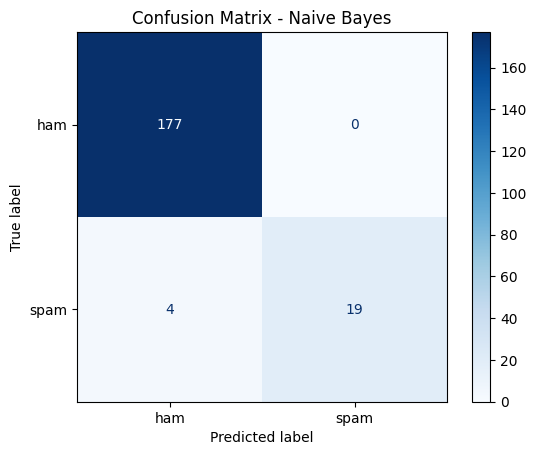

In [ ]:
print("=== MODEL 1: NAIVE BAYES + TF-IDF ===")

# Inisialisasi & Training
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# Prediksi & Evaluasi
y_pred_nb = nb_model.predict(X_test)
acc_nb = accuracy_score(y_test, y_pred_nb)

print(f"Akurasi Naive Bayes: {acc_nb:.4f}")
print("\nLaporan Klasifikasi:\n", classification_report(y_test, y_pred_nb))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_nb, cmap='Blues')
plt.title("Confusion Matrix - Naive Bayes")
plt.show()

=== MODEL 2: RANDOM FOREST + TF-IDF ===
Akurasi Random Forest: 0.9550

Laporan Klasifikasi:
               precision    recall  f1-score   support

         ham       0.96      0.99      0.98       177
        spam       0.94      0.65      0.77        23

    accuracy                           0.95       200
   macro avg       0.95      0.82      0.87       200
weighted avg       0.95      0.95      0.95       200



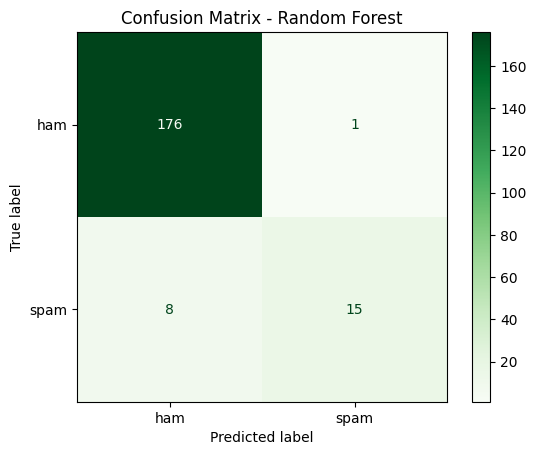

In [ ]:
print("=== MODEL 2: RANDOM FOREST + TF-IDF ===")

# Inisialisasi & Training
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Prediksi & Evaluasi
y_pred_rf = rf_model.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"Akurasi Random Forest: {acc_rf:.4f}")
print("\nLaporan Klasifikasi:\n", classification_report(y_test, y_pred_rf))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, cmap='Greens')
plt.title("Confusion Matrix - Random Forest")
plt.show()

In [ ]:
print("=== KESIMPULAN AKHIR ===")
print(f"Akurasi Naive Bayes   : {acc_nb:.4f}")
print(f"Akurasi Random Forest : {acc_rf:.4f}")

if acc_nb > acc_rf:
    print("\n>> Kombinasi Terbaik: Naive Bayes + TF-IDF")
elif acc_rf > acc_nb:
    print("\n>> Kombinasi Terbaik: Random Forest + TF-IDF")
else:
    print("\n>> Kedua model memiliki performa setara.")

=== KESIMPULAN AKHIR ===
Akurasi Naive Bayes   : 0.9800
Akurasi Random Forest : 0.9550

>> Kombinasi Terbaik: Naive Bayes + TF-IDF
